# Spline-state Kalman filter — IV surface

State space: spline coefficients θ ∈ ℝⁿ parametrize the whole smile.  
Each quote from any option yields one scalar observation; the full surface is updated jointly.  
Trades are evaluated out-of-sample against the surface state at their matched quote timestamp.

In [70]:
import importlib as imp
import os
import sys
from datetime import date, datetime

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# shared functions (unchanged from individual filter)
sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)

# new spline-specific modules (to be built alongside this notebook)
sys.path.insert(0, os.path.dirname(os.path.abspath("__file__")))

os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"
os.environ["QUANTDATA_TRAINING_DATA"] = "!/quantdata/training"
os.environ["QUANTDATA_PROCESSING_DATA"] = "!/quantdata/processing"
os.environ["QUANTDATA_CACHE_MODE"] = "on"
os.environ["QUANTDATA_TEST_MODE"] = "0"

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

# shared, unmodified
import surface_kalman_filters  # build_iv_observations + run_spline_surface_kalman

# new spline modules (files to be created in this folder)
import surface_model  # SurfaceModelConfig + basis evaluation

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.utils as utils
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


## Config — change these to experiment

In [93]:
# ── Pick model here ───────────────────────────────────────────────────────────
# surface_model.QUAD_SLICE_MODEL — 3 params, a+b·k+c·k²         linear KF, single expiry
# surface_model.SVI_SLICE_MODEL  — 5 params, SVI raw             EKF,    single expiry
# surface_model.SVI_MODEL        — 5 params, SVI raw × √T        EKF,    multi-expiry
# surface_model.TANH_MODEL       — 3 params, a√T(1+tanh(bk+ck²)) EKF,   multi-expiry
# surface_model.SSVI_SLICE_MODEL — 3 params, SSVI [ϑ,ρ,ζ]        EKF,    single expiry
#   SSVI = surface-SVI collapsed to one maturity (Gatheral–Jacquier 1204.0646).
#   Fewer dof than raw SVI, but project() enforces the closed-form butterfly-free
#   region ϑζ(1+|ρ|)<4, ϑζ²(1+|ρ|)≤4 at every step — guaranteed arb-free smile.
model = surface_model.SSVI_SLICE_MODEL

cfg = surface_model.SurfaceModelConfig(
    model=model,
    Q_scale=1e-10,  # multiplied by q_diag_weights per parameter
    # "diagonal" lets the model's q_diag_weights act: SSVI moves the level (ϑ)
    # fast but the shape (ρ, ζ) slowly, which a flat "scaled_identity" Q ignores.
    Q_structure="diagonal",
    P0_scale=1.0,
)
print(f"Model     : {cfg.model.name}  |  n_params={cfg.n_params}")
print(f"Initial θ : {cfg.model.initial_theta(cfg)}")
print(f"Q diagonal: {surface_model.build_Q(cfg).diagonal().round(4)}")

Model     : ssvi_slice  |  n_params=3
Initial θ : [ 1.5e-04 -7.0e-01  1.0e+01]
Q diagonal: [0. 0. 0.]


## Data loading

In [94]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [95]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

## Build IV observation stream

`build_iv_observations` runs Phases 1+2 of the existing pipeline (fetch, clean, compute implied forward, compute IV) but stops before any per-option Kalman step.  
It returns two long DataFrames — one for quotes, one for matched trades — each with columns:
`ts_ns, log_moneyness, T, observed_iv, bid_iv, ask_iv, R_iv, strike, is_call`

In [96]:
imp.reload(surface_kalman_filters)
imp.reload(surface_model)

df_quotes_iv, df_trades_iv = surface_kalman_filters.build_iv_observations(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)
print(f"Quotes: {df_quotes_iv.shape[0]:,} rows, {df_quotes_iv['strike'].n_unique()} strikes")
print(f"Trades: {df_trades_iv.shape[0]:,} rows")
df_quotes_iv.head()

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
Quotes: 2,115,510 rows, 25 strikes
Trades: 74,099 rows


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.136858,0.134075,0.139497,0.000007,0.09,0.11,470.43,null
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43,null
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,null
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,null


## Run spline surface Kalman filter

`run_spline_surface_kalman` takes the merged observation stream and config.  
At each quote tick it computes `H = basis(log_moneyness, T)` and runs one KF update on the shared state θ.  
Returns:
- `df_quotes_result` — quotes with `spline_iv` column (surface evaluated at that option's coordinates)
- `df_trades_result` — trades with `spline_matched` and `trade_residual` columns

In [97]:
# OTM filter: keep puts where K < F (k < 0) and calls where K >= F (k >= 0).
# ITM options have wide spreads and their IV is unreliable — exclude from training.
# Trades are kept unfiltered for fair out-of-sample evaluation.
df_quotes_otm = df_quotes_iv.filter(
    (pl.col("is_call") & (pl.col("log_moneyness") >= 0))
    | (~pl.col("is_call") & (pl.col("log_moneyness") < 0))
)
print(f"Quotes before OTM filter: {df_quotes_iv.shape[0]:,}  →  after: {df_quotes_otm.shape[0]:,}")

df_quotes_result, df_trades_result, df_state = surface_kalman_filters.run_spline_surface_kalman(
    df_quotes_iv=df_quotes_otm,
    df_trades_iv=df_trades_iv,
    cfg=cfg,
)
df_quotes_result.head()

Quotes before OTM filter: 2,115,510  →  after: 978,524


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor,spline_iv,spline_prior_iv,kalman_price,kalman_price_prior
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.136858,0.134075,0.139497,0.000007,0.09,0.11,470.43,null,0.136581,0.145574,0.099005,0.134981
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null,0.137319,0.136581,0.101732,0.099005
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,null,0.138814,0.139596,0.253036,0.258275
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,null,0.137574,0.137782,0.160773,0.161827
2024-01-03 09:30:00.008504576 EST,466.0,false,-0.009462,0.006217,0.141883,0.140865,0.142848,9.8379e-7,0.57,0.59,470.43,null,0.14184,0.150213,0.580018,0.66798


In [98]:
df_trades_result.head()

ts_ns,quote_ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,bid_price,ask_price,forward,discount_factor,ts_ns_right,spline_matched,kalman_price,trade_residual
"datetime[ns, America/New_York]","datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,"datetime[ns, America/New_York]",f64,f64,f64
2024-01-03 09:30:00.102 EST,2024-01-03 09:30:00.008504576 EST,466.0,false,-0.009547,0.006217,0.141628,0.141628,0.143618,0.57,0.59,470.47,null,2024-01-03 09:30:00.008504576 EST,0.141863,0.572402,-0.000235
2024-01-03 09:30:00.311 EST,2024-01-03 09:30:00.008504576 EST,466.0,false,-0.010131,0.006217,0.14783,0.146837,0.148818,0.57,0.59,470.745,0.999395,2024-01-03 09:30:00.008504576 EST,0.142018,0.522209,0.005812
2024-01-03 09:30:00.031 EST,2024-01-03 09:30:00.031845888 EST,479.0,true,0.01799,0.006217,0.130745,0.130745,0.1441,0.08,0.13,470.46,null,2024-01-03 09:30:00.031845888 EST,0.139373,0.11106,-0.008628
2024-01-03 09:30:00.051 EST,2024-01-03 09:30:00.044120064 EST,480.0,true,0.020075,0.006217,0.142976,0.139489,0.142976,0.07,0.08,470.46,null,2024-01-03 09:30:00.044120064 EST,0.140741,0.073592,0.002235
2024-01-03 09:30:00.102 EST,2024-01-03 09:30:00.112472576 EST,463.0,false,-0.016005,0.006217,0.154323,0.149303,0.151009,0.22,0.23,470.47,null,2024-01-03 09:30:00.112472576 EST,0.149956,0.223922,0.004367


## Quick residual check

In [99]:
df_trades_clean = df_trades_result.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse = float((df_trades_clean["trade_residual"] ** 2).mean() ** 0.5)
print(f"Trade RMSE (IV): {rmse:.5f}")
print(f"Rows: {df_trades_clean.shape[0]:,}")

Trade RMSE (IV): 0.00354
Rows: 74,094


## Smile snapshot — spline surface vs raw IV

In [106]:
# ── Pick a snapshot ──────────────────────────────────────────────────────────
row_idx = df_quotes_result.shape[0] * 4 // 5  # ← change this
snapshot_ts = df_quotes_result["ts_ns"][row_idx]

# θ at the snapshot: last state update at or before snapshot_ts
state_row = df_state.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
theta_snap = np.array([state_row[f"theta_{j}"][0] for j in range(cfg.n_params)])

# Use the median T of options alive at the snapshot time as the reference maturity
snap_quotes = (
    df_quotes_result.filter(pl.col("ts_ns") <= snapshot_ts).group_by(["strike", "is_call"]).last()
)
snap_T = float(snap_quotes["T"].median())

# ── Evaluate the continuous fitted smile ──────────────────────────────────────
k_grid = np.linspace(-0.15, 0.15, 300)
iv_fit = np.array([cfg.model.observe(theta_snap, k, snap_T)[0] for k in k_grid])

# ── Plot ──────────────────────────────────────────────────────────────────────
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=k_grid,
        y=iv_fit,
        mode="lines",
        name=f"fitted ({cfg.model.name})",
        line=dict(color="darkgreen", width=2),
    )
)
fig.add_trace(
    go.Scatter(
        x=snap_quotes.filter(pl.col("is_call"))["log_moneyness"].to_list(),
        y=snap_quotes.filter(pl.col("is_call"))["observed_iv"].to_list(),
        mode="markers",
        name="calls — observed",
        marker=dict(color="royalblue", symbol="x", size=8),
    )
)
fig.add_trace(
    go.Scatter(
        x=snap_quotes.filter(~pl.col("is_call"))["log_moneyness"].to_list(),
        y=snap_quotes.filter(~pl.col("is_call"))["observed_iv"].to_list(),
        mode="markers",
        name="puts — observed",
        marker=dict(color="firebrick", symbol="x", size=8),
    )
)

fig.update_layout(
    title=f"[{cfg.model.name}] Fitted smile — T={snap_T:.3f}y  |  ts={snapshot_ts}",
    xaxis_title="log-moneyness  k = log(K/F)",
    yaxis_title="Implied Vol",
)
fig.show()

# Parameter names per model so the printout is meaningful (falls back to theta_i).
_param_names = {
    "svi_slice": ["a", "b", "rho", "m", "sigma"],
    "svi": ["a", "b", "rho", "m", "sigma"],
    "ssvi_slice": ["theta", "rho", "zeta"],
    "quad_slice": ["a", "b", "c"],
    "tanh": ["a", "b", "c"],
}.get(cfg.model.name, [f"theta_{j}" for j in range(cfg.n_params)])
print(f"θ = {dict(zip(_param_names[: cfg.n_params], theta_snap.round(4)))}")

θ = {'theta': np.float64(0.0001), 'rho': np.float64(-0.1701), 'zeta': np.float64(49.6251)}


## Full evaluation

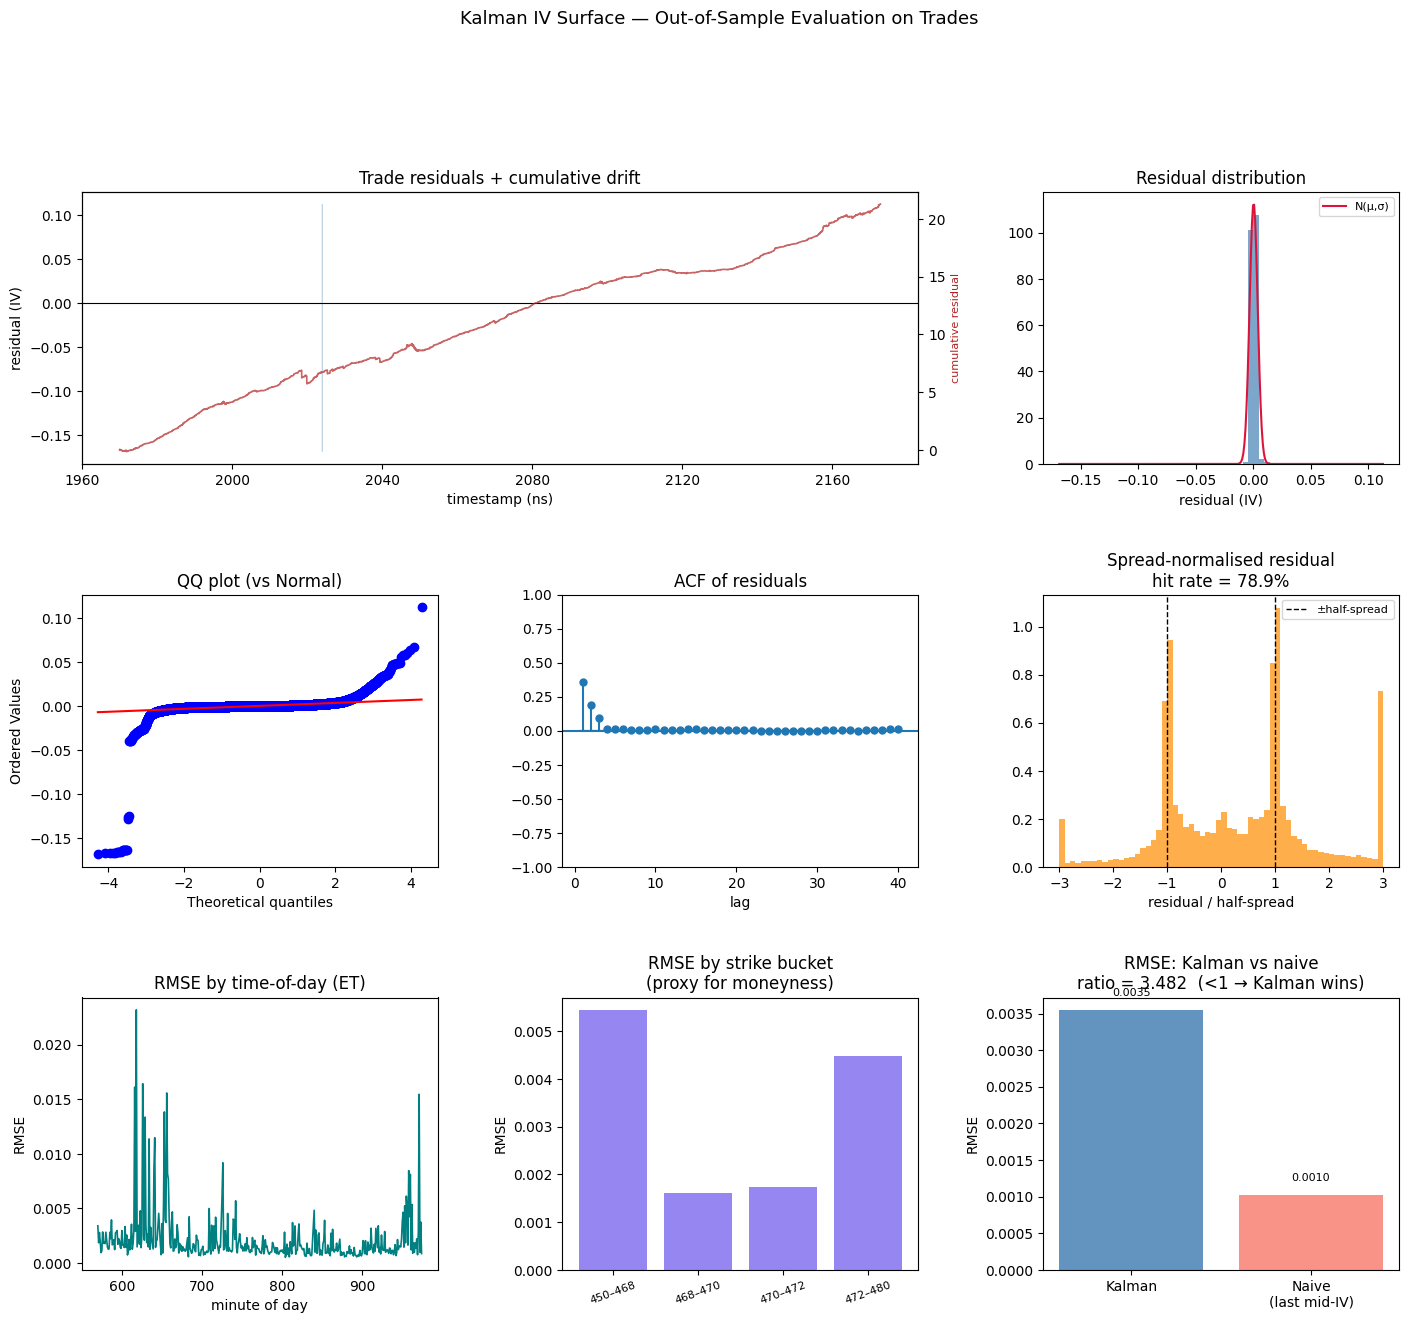

RMSE                 0.00354
MAE                  0.00096
Bias                 0.00029
Hit rate             78.9%
Naive RMSE           0.00102
RMSE ratio           3.482  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
         lb_stat  lb_pvalue
10  13000.890896        0.0
20  13044.141958        0.0


In [107]:
# evaluate_kalman_iv expects 'kalman_matched' column on trades — rename to reuse it
metrics = evaluate_kalman_iv(
    df_quotes_iv=df_quotes_result.rename({"spline_iv": "kalman_iv"}),
    df_trades_iv=df_trades_result.rename({"spline_matched": "kalman_matched"}),
)

## Compare vs individual per-option Kalman (baseline)

In [111]:
# Run the old filter for comparison
df_quotes_indiv, df_trades_indiv = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
    simple=False,
)
df_trades_indiv_clean = df_trades_indiv.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse_indiv = float((df_trades_indiv_clean["trade_residual"] ** 2).mean() ** 0.5)

print(f"Spline surface RMSE : {rmse:.5f}")
print(f"Individual KF RMSE  : {rmse_indiv:.5f}")
print(f"Ratio (spline/indiv): {rmse / rmse_indiv:.3f}  (<1 → spline wins)")

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000: dropping 64 bad quotes (sub-tick bid×64 (first=2024-01-03 10:00:01.421753-05:00))
O:SPY240105C00483000: dropping 842 bad quotes (sub-tick bid×842 (first=2024-01-03 09:30:00.060278-05:00), zero bid size×1 (first=2024-01-03 09:30:00.060278-05:00))
O:SPY240105C00484000: dropping 2129 bad quotes

In [112]:
df_quotes_iv

ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.136858,0.134075,0.139497,0.000007,0.09,0.11,470.43,null
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43,null
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,null
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,null
…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,469.0,true,-0.000117,0.005447,0.134494,0.134132,0.134856,1.3110e-7,1.88,1.89,469.055,0.999328
2024-01-03 16:14:59.884593152 EST,474.0,false,0.010487,0.005447,0.138856,0.132675,0.144803,0.000037,5.28,5.38,469.055,0.999328
2024-01-03 16:14:59.884598272 EST,472.0,false,0.006259,0.005447,0.134109,0.131454,0.136743,0.000007,3.66,3.72,469.055,0.999328


## Snapshot comparison — KF single-strike vs SSVI

Same market snapshot, two models overlaid:
- **SSVI (spline KF)** — parametric smile fitted jointly over all strikes via the surface Kalman filter
- **KF single-strike** — per-option posterior IV from the individual Kalman filter (calls blue, puts red)
- **×** markers — raw observed mid-IVs at that timestamp

In [113]:
# ── Same snapshot: KF single-strike vs SSVI ──────────────────────────────────
# Reuses snapshot_ts / theta_snap / snap_T / k_grid / iv_fit / snap_quotes
# from the "Smile snapshot" cell above.
# df_quotes_indiv comes from the "Compare vs individual" cell.

# Last posterior kalman_iv per option at the snapshot
snap_indiv = (
    df_quotes_indiv.filter(pl.col("ts_ns") <= snapshot_ts)
    .group_by(["strike", "is_call"])
    .last()
    .with_columns((pl.col("strike") / pl.col("forward")).log().alias("log_moneyness"))
    .sort("log_moneyness")
)

fig = go.Figure()

# SSVI continuous fit (already computed above)
fig.add_trace(
    go.Scatter(
        x=k_grid,
        y=iv_fit,
        mode="lines",
        name="SSVI (spline KF)",
        line=dict(color="darkgreen", width=2.5),
    )
)

# KF single-strike — calls
kf_calls = snap_indiv.filter(pl.col("is_call"))
fig.add_trace(
    go.Scatter(
        x=kf_calls["log_moneyness"].to_list(),
        y=kf_calls["kalman_iv"].to_list(),
        mode="lines+markers",
        name="KF single-strike — calls",
        line=dict(color="royalblue", width=1.5),
        marker=dict(symbol="circle", size=7),
    )
)

# KF single-strike — puts
kf_puts = snap_indiv.filter(~pl.col("is_call"))
fig.add_trace(
    go.Scatter(
        x=kf_puts["log_moneyness"].to_list(),
        y=kf_puts["kalman_iv"].to_list(),
        mode="lines+markers",
        name="KF single-strike — puts",
        line=dict(color="firebrick", width=1.5),
        marker=dict(symbol="circle", size=7),
    )
)

# Raw observed IVs for reference
obs_calls = snap_quotes.filter(pl.col("is_call")).sort("log_moneyness")
obs_puts = snap_quotes.filter(~pl.col("is_call")).sort("log_moneyness")
fig.add_trace(
    go.Scatter(
        x=obs_calls["log_moneyness"].to_list(),
        y=obs_calls["observed_iv"].to_list(),
        mode="markers",
        name="observed — calls",
        marker=dict(color="royalblue", symbol="x", size=8, opacity=0.45),
    )
)
fig.add_trace(
    go.Scatter(
        x=obs_puts["log_moneyness"].to_list(),
        y=obs_puts["observed_iv"].to_list(),
        mode="markers",
        name="observed — puts",
        marker=dict(color="firebrick", symbol="x", size=8, opacity=0.45),
    )
)

fig.update_layout(
    title=f"KF single-strike vs SSVI  |  T={snap_T:.3f}y  |  {snapshot_ts}",
    xaxis_title="log-moneyness  k = log(K/F)",
    yaxis_title="Implied Vol",
    legend=dict(x=0.01, y=0.99),
)
fig.show()